# Homework 6.1 - Steps 6-8

## Attention Interpretation, Generation, and Lorenz Dynamics Checks

This notebook uses the validation-selected attention model from Steps 4, 5, and 9.

It has two goals:

1. inspect what the learned attention weights emphasize;
2. compare attention-generated trajectories with both true Lorenz trajectories and the Markov baseline.

Task 8 is explicitly marked not applicable because the chosen system is Lorenz rather than Kirchhoff.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

import torch
from torch import nn

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_1"

TOKEN_DIR = DATA_DIR / "token_books"
TRAJECTORY_DIR = DATA_DIR / "trajectories"
MODEL_DIR = DATA_DIR / "attention_models"

ATTENTION_GENERATED_DIR = (
    DATA_DIR
    / "attention_generated_sequences"
)

MARKOV_GENERATED_DIR = (
    DATA_DIR
    / "markov_generated_sequences"
)

ATTENTION_GENERATED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MARKOV_GENERATED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

config = json.loads(
    (
        DATA_DIR
        / "baseline_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

attention_selection = json.loads(
    (
        DATA_DIR
        / "task4_5_9_selected_attention_model.json"
    ).read_text(
        encoding="utf-8"
    )
)

markov_selection = json.loads(
    (
        DATA_DIR
        / "task3_selected_markov_baseline.json"
    ).read_text(
        encoding="utf-8"
    )
)

SELECTED_L = int(
    attention_selection[
        "selected_attention_context_length"
    ]
)

SELECTED_M = int(
    markov_selection[
        "selected_context_length_m"
    ]
)

VOCAB_SIZE = int(
    config[
        "possible_vocabulary_size"
    ]
)

DT = float(
    config[
        "sampling_interval_dt"
    ]
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

GENERATION_SEED = 63867
GENERATIONS_PER_TEST_SEED = 10

rng = np.random.default_rng(
    GENERATION_SEED
)

print("Selected attention context L:", SELECTED_L)
print("Selected Markov context m:", SELECTED_M)
print("Device:", DEVICE)

Selected attention context L: 32
Selected Markov context m: 3
Device: cuda


## Reconstruct the selected attention model

In [2]:
class SingleHeadCausalSelfAttention(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()

        self.embed_dim = embed_dim

        self.query = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.key = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.value = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.output = nn.Linear(
            embed_dim,
            embed_dim,
            bias=False,
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(
        self,
        x,
        return_weights=False,
    ):
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = (
            q
            @ k.transpose(-2, -1)
        ) / math.sqrt(
            self.embed_dim
        )

        length = x.shape[1]

        causal_mask = torch.triu(
            torch.ones(
                length,
                length,
                dtype=torch.bool,
                device=x.device,
            ),
            diagonal=1,
        )

        scores = scores.masked_fill(
            causal_mask,
            float("-inf"),
        )

        weights = torch.softmax(
            scores,
            dim=-1,
        )

        attended = (
            self.dropout(weights)
            @ v
        )

        output = self.output(
            attended
        )

        if return_weights:
            return output, weights

        return output


class SmallCausalAttentionPredictor(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        context_length,
        embed_dim,
        ff_dim,
        dropout,
    ):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(
            vocabulary_size,
            embed_dim,
        )

        self.position_embedding = nn.Embedding(
            context_length,
            embed_dim,
        )

        self.attention = (
            SingleHeadCausalSelfAttention(
                embed_dim,
                dropout,
            )
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(
                embed_dim,
                ff_dim,
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(
                ff_dim,
                embed_dim,
            ),
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.output = nn.Linear(
            embed_dim,
            vocabulary_size,
        )

    def forward(
        self,
        tokens,
        return_attention=False,
    ):
        _, length = tokens.shape

        positions = torch.arange(
            length,
            device=tokens.device,
        )

        x = (
            self.token_embedding(tokens)
            + self.position_embedding(
                positions
            )[None, :, :]
        )

        attention_output, weights = (
            self.attention(
                x,
                return_weights=True,
            )
        )

        x = self.norm1(
            x + attention_output
        )

        x = self.norm2(
            x + self.feed_forward(x)
        )

        logits = self.output(
            x[:, -1, :]
        )

        if return_attention:
            return logits, weights

        return logits


checkpoint_path = (
    MODEL_DIR
    / (
        f"attention_context_"
        f"{SELECTED_L:02d}.pt"
    )
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
)

attention_model = (
    SmallCausalAttentionPredictor(
        vocabulary_size=checkpoint[
            "vocabulary_size"
        ],
        context_length=checkpoint[
            "context_length"
        ],
        embed_dim=checkpoint[
            "embed_dim"
        ],
        ff_dim=checkpoint[
            "ff_dim"
        ],
        dropout=checkpoint[
            "dropout"
        ],
    ).to(DEVICE)
)

attention_model.load_state_dict(
    checkpoint["state_dict"]
)

attention_model.eval()

print("Loaded:", checkpoint_path.resolve())

Loaded: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\attention_models\attention_context_32.pt


In [3]:
def load_token_books(split_name):
    books = []

    for path in sorted(
        (TOKEN_DIR / split_name).glob("book_*.csv")
    ):
        frame = pd.read_csv(path)

        books.append(
            frame["token"].to_numpy(
                dtype=np.int64
            )
        )

    return books


def load_continuous_books(split_name):
    books = []

    for path in sorted(
        (TRAJECTORY_DIR / split_name).glob("book_*.npz")
    ):
        data = np.load(path)
        books.append(data["states"])

    return books


train_books = load_token_books("train")
validation_books = load_token_books("validation")
test_books = load_token_books("test")

train_continuous = load_continuous_books("train")
validation_continuous = load_continuous_books("validation")
test_continuous = load_continuous_books("test")

box_vocab = pd.read_csv(
    DATA_DIR
    / "baseline_box_vocabulary.csv"
).sort_values("token")

centers = box_vocab[
    [
        "x_center",
        "y_center",
        "z_center",
    ]
].to_numpy(dtype=float)


def tokens_to_centers(tokens):
    return centers[
        np.asarray(
            tokens,
            dtype=np.int64,
        )
    ]


validation_center_books = [
    tokens_to_centers(sequence)
    for sequence in validation_books
]

test_center_books = [
    tokens_to_centers(sequence)
    for sequence in test_books
]

# Task 6: visualize attention weights

For a selected context, the model returns

$$
A_{ij},
\qquad
j\le i.
$$

Two examples are selected reproducibly:

1. a context immediately before a lobe switch;
2. a context that remains entirely within one lobe.

The lobe label is based on the sign of the token box-center $$x$$ coordinate.

In [4]:
def get_attention_for_window(
    token_window,
):
    tensor = torch.as_tensor(
        token_window[None, :],
        dtype=torch.long,
        device=DEVICE,
    )

    with torch.no_grad():
        logits, weights = (
            attention_model(
                tensor,
                return_attention=True,
            )
        )

    return (
        logits.cpu().numpy()[0],
        weights.cpu().numpy()[0],
    )


test_sequence = test_books[0]
test_centers = test_center_books[0]

x_sign = np.where(
    test_centers[:, 0] >= 0.0,
    1,
    -1,
)

switch_positions = (
    np.flatnonzero(
        x_sign[1:]
        != x_sign[:-1]
    )
    + 1
)

switch_target = next(
    int(position)
    for position in switch_positions
    if position >= SELECTED_L
)

within_lobe_target = None

for target in range(
    SELECTED_L,
    len(test_sequence),
):
    context_sign = x_sign[
        target-SELECTED_L:target
    ]

    if np.all(
        context_sign
        == context_sign[0]
    ):
        within_lobe_target = target
        break

if within_lobe_target is None:
    raise RuntimeError(
        "Could not find a fully within-lobe context."
    )

examples = {
    "near_lobe_switch": (
        switch_target
    ),
    "within_one_lobe": (
        within_lobe_target
    ),
}

print(examples)

{'near_lobe_switch': 102, 'within_one_lobe': 32}


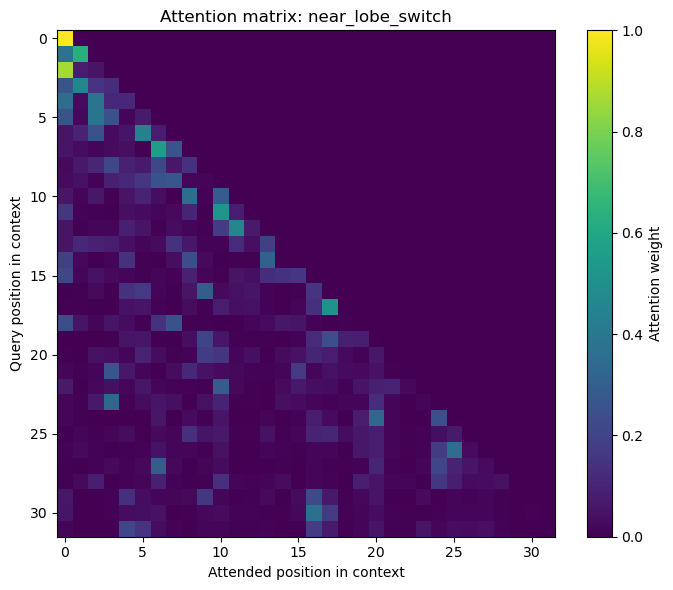

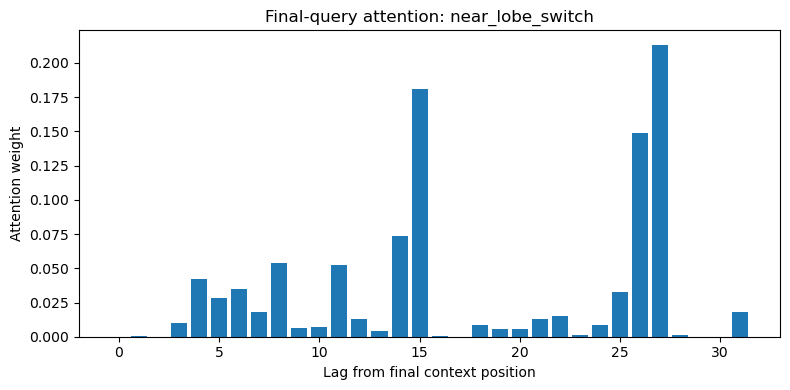

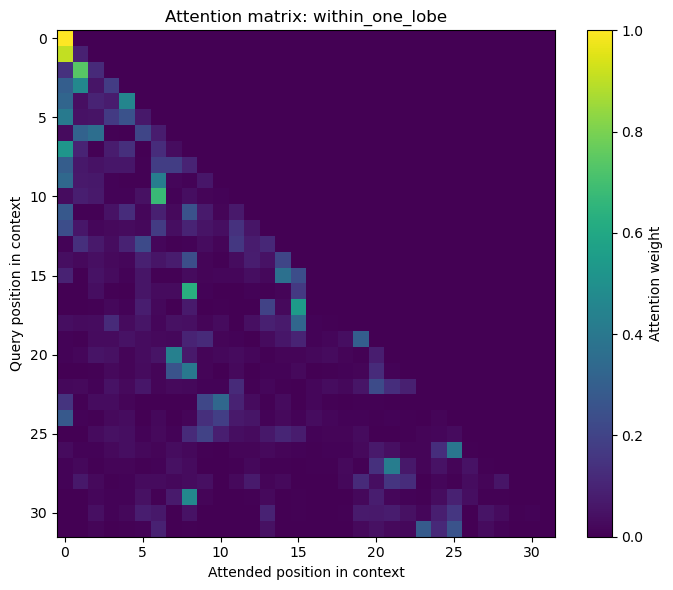

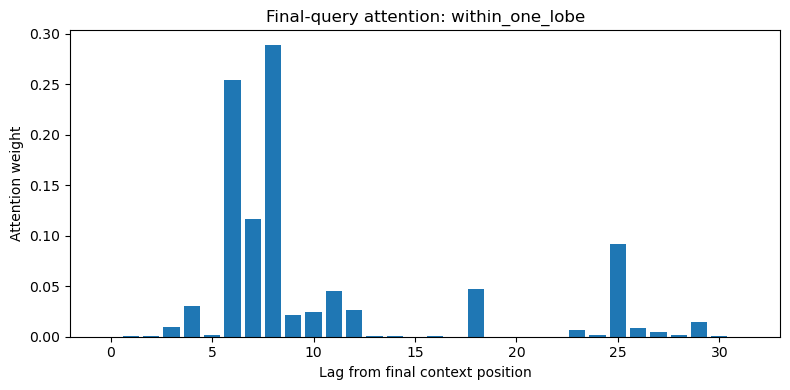

         example  target_position  predicted_token  true_token  correct
near_lobe_switch              102              795         939    False
 within_one_lobe               32              616         616     True


In [5]:
attention_example_rows = []

for label, target in examples.items():
    window = test_sequence[
        target-SELECTED_L:target
    ]

    logits, weights = (
        get_attention_for_window(
            window
        )
    )

    prediction = int(
        np.argmax(logits)
    )

    truth = int(
        test_sequence[target]
    )

    attention_example_rows.append({
        "example": label,
        "target_position": target,
        "predicted_token": prediction,
        "true_token": truth,
        "correct": (
            prediction == truth
        ),
    })

    plt.figure(
        figsize=(7, 6)
    )

    plt.imshow(
        weights,
        aspect="auto",
        origin="upper",
    )

    plt.xlabel(
        "Attended position in context"
    )

    plt.ylabel(
        "Query position in context"
    )

    plt.title(
        f"Attention matrix: {label}"
    )

    plt.colorbar(
        label="Attention weight"
    )

    plt.tight_layout()

    matrix_path = (
        RESULT_DIR
        / (
            f"step6_attention_matrix_"
            f"{label}.png"
        )
    )

    plt.savefig(
        matrix_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    final_weights = weights[-1]

    lags = np.arange(
        SELECTED_L - 1,
        -1,
        -1,
    )

    plt.figure(
        figsize=(8, 4)
    )

    plt.bar(
        lags,
        final_weights,
    )

    plt.xlabel(
        "Lag from final context position"
    )

    plt.ylabel(
        "Attention weight"
    )

    plt.title(
        f"Final-query attention: {label}"
    )

    plt.tight_layout()

    profile_path = (
        RESULT_DIR
        / (
            f"step6_attention_profile_"
            f"{label}.png"
        )
    )

    plt.savefig(
        profile_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


attention_examples = pd.DataFrame(
    attention_example_rows
)

examples_path = (
    DATA_DIR
    / "task6_attention_examples.csv"
)

attention_examples.to_csv(
    examples_path,
    index=False,
)

print(attention_examples.to_string(index=False))

## Quantify how far backward attention reaches

For the final query in a context, define the expected attention lag

$$
D_i
=
\sum_{j=1}^{L}
A_{Lj}(L-j).
$$

Large $$D_i$$ means that more attention is placed farther into the past.

We compare this quantity for targets that cross a lobe boundary and targets that do not.

In [6]:
attention_lag_rows = []

for book_index, sequence in enumerate(
    test_books
):
    center_states = test_center_books[
        book_index
    ]

    signs = np.where(
        center_states[:, 0] >= 0.0,
        1,
        -1,
    )

    windows = []
    metadata = []

    for target in range(
        SELECTED_L,
        len(sequence),
    ):
        windows.append(
            sequence[
                target-SELECTED_L:target
            ]
        )

        metadata.append({
            "target_position": (
                target
            ),
            "is_lobe_switch_target": (
                signs[target]
                != signs[target - 1]
            ),
        })

    windows = np.asarray(
        windows,
        dtype=np.int64,
    )

    batch_size = 512

    for start in range(
        0,
        len(windows),
        batch_size,
    ):
        batch = torch.as_tensor(
            windows[
                start:start+batch_size
            ],
            dtype=torch.long,
            device=DEVICE,
        )

        with torch.no_grad():
            _, weights = (
                attention_model(
                    batch,
                    return_attention=True,
                )
            )

        final_weights = (
            weights[:, -1, :]
            .cpu()
            .numpy()
        )

        lags = np.arange(
            SELECTED_L - 1,
            -1,
            -1,
            dtype=float,
        )

        expected_lags = (
            final_weights
            * lags[None, :]
        ).sum(axis=1)

        for local_index, lag_value in enumerate(
            expected_lags
        ):
            info = metadata[
                start + local_index
            ]

            attention_lag_rows.append({
                "book": book_index,
                "target_position": (
                    info[
                        "target_position"
                    ]
                ),
                "is_lobe_switch_target": (
                    info[
                        "is_lobe_switch_target"
                    ]
                ),
                "expected_attention_lag": (
                    float(lag_value)
                ),
            })


attention_lag = pd.DataFrame(
    attention_lag_rows
)

lag_path = (
    DATA_DIR
    / "task6_attention_lag_by_target.csv"
)

attention_lag.to_csv(
    lag_path,
    index=False,
)

lag_summary = (
    attention_lag
    .groupby(
        "is_lobe_switch_target"
    )[
        "expected_attention_lag"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "std",
        ]
    )
)

summary_path = (
    DATA_DIR
    / "task6_attention_lag_summary.csv"
)

lag_summary.to_csv(
    summary_path
)

print(lag_summary)

                       count       mean     median       std
is_lobe_switch_target                                       
False                  12057  13.252350  13.173839  3.755743
True                     133  16.259528  16.581633  2.160958


# Task 7: generate new token trajectories

Two discrete generators are compared:

1. the validation-selected Markov baseline;
2. the validation-selected attention model.

For each held-out test book, 10 stochastic continuations are generated.

For a fair generator comparison, **both models receive the same first `SELECTED_L = 32` true test tokens as an initial prefix**. The Markov model then uses only its most recent `SELECTED_M = 3` tokens when choosing each subsequent transition, while the attention model uses its most recent 32 tokens. Future held-out tokens are never supplied.

## Refit and generate from the Markov baseline

In [7]:
def fit_markov_models(
    books,
    max_order,
):
    models = {
        order: defaultdict(Counter)
        for order in range(
            1,
            max_order + 1,
        )
    }

    unigram = Counter()

    for sequence in books:
        unigram.update(
            sequence.tolist()
        )

        for order in range(
            1,
            max_order + 1,
        ):
            for i in range(
                order,
                len(sequence),
            ):
                history = tuple(
                    int(x)
                    for x in sequence[
                        i-order:i
                    ]
                )

                next_token = int(
                    sequence[i]
                )

                models[order][
                    history
                ][next_token] += 1

    return models, unigram


markov_models, markov_unigram = (
    fit_markov_models(
        train_books,
        SELECTED_M,
    )
)


def markov_counter(history):
    for order in range(
        min(
            SELECTED_M,
            len(history),
        ),
        0,
        -1,
    ):
        key = tuple(
            int(x)
            for x in history[-order:]
        )

        if key in markov_models[
            order
        ]:
            return (
                markov_models[
                    order
                ][key]
            )

    return markov_unigram


def sample_counter(counter, rng):
    tokens = np.array(
        list(counter.keys()),
        dtype=np.int64,
    )

    counts = np.array(
        list(counter.values()),
        dtype=float,
    )

    probabilities = (
        counts / counts.sum()
    )

    return int(
        rng.choice(
            tokens,
            p=probabilities,
        )
    )


markov_generated = []
markov_manifest_rows = []

for test_book_index, true_sequence in enumerate(
    test_books
):
    for replicate in range(
        GENERATIONS_PER_TEST_SEED
    ):
        generated = list(
            true_sequence[
                :SELECTED_L
            ]
        )

        while len(generated) < len(
            true_sequence
        ):
            counter = markov_counter(
                generated
            )

            generated.append(
                sample_counter(
                    counter,
                    rng,
                )
            )

        generated = np.asarray(
            generated,
            dtype=np.int64,
        )

        markov_generated.append(
            generated
        )

        output_path = (
            MARKOV_GENERATED_DIR
            / (
                f"seed_{test_book_index:02d}"
                f"_rep_{replicate:02d}.csv"
            )
        )

        pd.DataFrame({
            "sample_index": np.arange(
                len(generated)
            ),
            "token": generated,
        }).to_csv(
            output_path,
            index=False,
        )

        markov_manifest_rows.append({
            "seed_test_book": (
                test_book_index
            ),
            "replicate": replicate,
            "prefix_length": SELECTED_L,
            "length": len(generated),
            "file": str(
                output_path.relative_to(
                    PROJECT_ROOT
                )
            ),
        })


markov_manifest = pd.DataFrame(
    markov_manifest_rows
)

markov_manifest_path = (
    DATA_DIR
    / "task7_markov_generated_manifest.csv"
)

markov_manifest.to_csv(
    markov_manifest_path,
    index=False,
)

print(
    "Generated Markov sequences:",
    len(markov_generated),
)

Generated Markov sequences: 100


## Generate from the attention model

All 100 sequences are advanced in parallel. At each step, the model sees only the most recent selected attention context.

In [8]:
seed_rows = []
seed_metadata = []

for test_book_index, true_sequence in enumerate(
    test_books
):
    for replicate in range(
        GENERATIONS_PER_TEST_SEED
    ):
        seed_rows.append(
            true_sequence[
                :SELECTED_L
            ]
        )

        seed_metadata.append(
            (
                test_book_index,
                replicate,
            )
        )


target_length = len(
    test_books[0]
)

attention_generated_array = np.full(
    (
        len(seed_rows),
        target_length,
    ),
    -1,
    dtype=np.int64,
)

attention_generated_array[
    :,
    :SELECTED_L,
] = np.asarray(
    seed_rows,
    dtype=np.int64,
)

attention_rng = np.random.default_rng(
    GENERATION_SEED + 1
)

for position in range(
    SELECTED_L,
    target_length,
):
    context = (
        attention_generated_array[
            :,
            position-SELECTED_L:position,
        ]
    )

    tensor = torch.as_tensor(
        context,
        dtype=torch.long,
        device=DEVICE,
    )

    with torch.no_grad():
        logits = attention_model(
            tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        ).cpu().numpy()

    sampled = np.empty(
        len(seed_rows),
        dtype=np.int64,
    )

    for row_index in range(
        len(seed_rows)
    ):
        sampled[row_index] = int(
            attention_rng.choice(
                VOCAB_SIZE,
                p=probabilities[
                    row_index
                ],
            )
        )

    attention_generated_array[
        :,
        position,
    ] = sampled

    if (
        position % 250 == 0
        or position
        == target_length - 1
    ):
        print(
            "Generated through position",
            position,
        )


attention_generated = [
    row.copy()
    for row in attention_generated_array
]

attention_manifest_rows = []

for row_index, generated in enumerate(
    attention_generated
):
    test_book_index, replicate = (
        seed_metadata[row_index]
    )

    output_path = (
        ATTENTION_GENERATED_DIR
        / (
            f"seed_{test_book_index:02d}"
            f"_rep_{replicate:02d}.csv"
        )
    )

    pd.DataFrame({
        "sample_index": np.arange(
            len(generated)
        ),
        "token": generated,
    }).to_csv(
        output_path,
        index=False,
    )

    attention_manifest_rows.append({
        "seed_test_book": (
            test_book_index
        ),
        "replicate": replicate,
        "length": len(generated),
        "file": str(
            output_path.relative_to(
                PROJECT_ROOT
            )
        ),
    })


attention_manifest = pd.DataFrame(
    attention_manifest_rows
)

attention_manifest_path = (
    DATA_DIR
    / "task7_attention_generated_manifest.csv"
)

attention_manifest.to_csv(
    attention_manifest_path,
    index=False,
)

print(
    "Generated attention sequences:",
    len(attention_generated),
)

Generated through position 250
Generated through position 500
Generated through position 750
Generated through position 1000
Generated through position 1250
Generated attention sequences: 100


## Coarse Lorenz attractor-support comparison

Every discrete trajectory is mapped to box centers before comparison.

The continuous training-state point cloud is used as the geometric reference.

The threshold is fixed as the 95th percentile of validation **box-center** distances from that training cloud.

This is a representation-matched but intentionally weak support diagnostic.

In [9]:
training_cloud = np.vstack(
    train_continuous
)

tree = cKDTree(
    training_cloud
)

validation_center_cloud = np.vstack(
    validation_center_books
)

validation_distances = tree.query(
    validation_center_cloud,
    k=1,
)[0]

distance_threshold = float(
    np.quantile(
        validation_distances,
        0.95,
    )
)


def support_metrics(
    sequences,
    label,
):
    center_cloud = np.vstack([
        tokens_to_centers(
            sequence
        )
        for sequence in sequences
    ])

    distances = tree.query(
        center_cloud,
        k=1,
    )[0]

    return {
        "dataset": label,
        "representation": (
            "token box centers"
        ),
        "count": len(distances),
        "mean_distance": float(
            distances.mean()
        ),
        "median_distance": float(
            np.median(
                distances
            )
        ),
        "p95_distance": float(
            np.quantile(
                distances,
                0.95,
            )
        ),
        "fraction_within_validation_p95_threshold": float(
            np.mean(
                distances
                <= distance_threshold
            )
        ),
    }


support_table = pd.DataFrame([
    support_metrics(
        test_books,
        "true_test",
    ),
    support_metrics(
        markov_generated,
        "markov_generated",
    ),
    support_metrics(
        attention_generated,
        "attention_generated",
    ),
])

support_path = (
    DATA_DIR
    / "task7_support_comparison.csv"
)

support_table.to_csv(
    support_path,
    index=False,
)

print(
    "Validation box-center p95 threshold:",
    distance_threshold,
)

print()
print(support_table.to_string(index=False))

Validation box-center p95 threshold: 2.2208753594253934

            dataset    representation  count  mean_distance  median_distance  p95_distance  fraction_within_validation_p95_threshold
          true_test token box centers  12510       0.877832         0.747042      2.220875                                  0.951079
   markov_generated token box centers 125100       0.862722         0.723608      2.220875                                  0.952022
attention_generated token box centers 125100       0.890884         0.764908      2.225257                                  0.947906


## Two-lobe switching comparison

The two coarse lobes are defined by the sign of the box-center $$x$$ coordinate.

We compare:

- switches per 1000 steps;
- mean and median residence time.

In [10]:
def lobe_residence_lengths(
    x_values
):
    labels = np.where(
        x_values >= 0.0,
        1,
        -1,
    )

    change_indices = (
        np.flatnonzero(
            labels[1:]
            != labels[:-1]
        )
        + 1
    )

    boundaries = np.concatenate(
        [
            [0],
            change_indices,
            [len(labels)],
        ]
    )

    return np.diff(
        boundaries
    )


def switching_metrics(
    sequences,
    label,
):
    rows = []

    for sequence_index, sequence in enumerate(
        sequences
    ):
        states = tokens_to_centers(
            sequence
        )

        residence_lengths = (
            lobe_residence_lengths(
                states[:, 0]
            )
        )

        switches = max(
            0,
            len(residence_lengths) - 1,
        )

        rows.append({
            "dataset": label,
            "sequence": (
                sequence_index
            ),
            "samples": len(sequence),
            "switches": switches,
            "switches_per_1000_steps": (
                1000.0
                * switches
                / max(
                    1,
                    len(sequence) - 1,
                )
            ),
            "mean_residence_steps": float(
                residence_lengths.mean()
            ),
            "median_residence_steps": float(
                np.median(
                    residence_lengths
                )
            ),
            "mean_residence_time": float(
                residence_lengths.mean()
                * DT
            ),
        })

    return pd.DataFrame(rows)


switching_table = pd.concat(
    [
        switching_metrics(
            test_books,
            "true_test",
        ),
        switching_metrics(
            markov_generated,
            "markov_generated",
        ),
        switching_metrics(
            attention_generated,
            "attention_generated",
        ),
    ],
    ignore_index=True,
)

switching_path = (
    DATA_DIR
    / "task7_lobe_switching_comparison.csv"
)

switching_table.to_csv(
    switching_path,
    index=False,
)

summary = (
    switching_table
    .groupby("dataset")
    [
        [
            "switches_per_1000_steps",
            "mean_residence_time",
        ]
    ]
    .agg(
        [
            "mean",
            "median",
            "std",
        ]
    )
)

summary_path = (
    DATA_DIR
    / "task7_lobe_switching_summary.csv"
)

summary.to_csv(
    summary_path
)

print(summary)

                    switches_per_1000_steps                   \
                                       mean median       std   
dataset                                                        
attention_generated                  25.216   24.0  8.381590   
markov_generated                     10.760   10.4  2.038419   
true_test                            10.960   10.4  2.720784   

                    mean_residence_time                      
                                   mean    median       std  
dataset                                                      
attention_generated            0.850592  0.807097  0.280748  
markov_generated               1.789179  1.787143  0.339931  
true_test                      1.777754  1.787143  0.373128  


## Visual comparison for one held-out seed

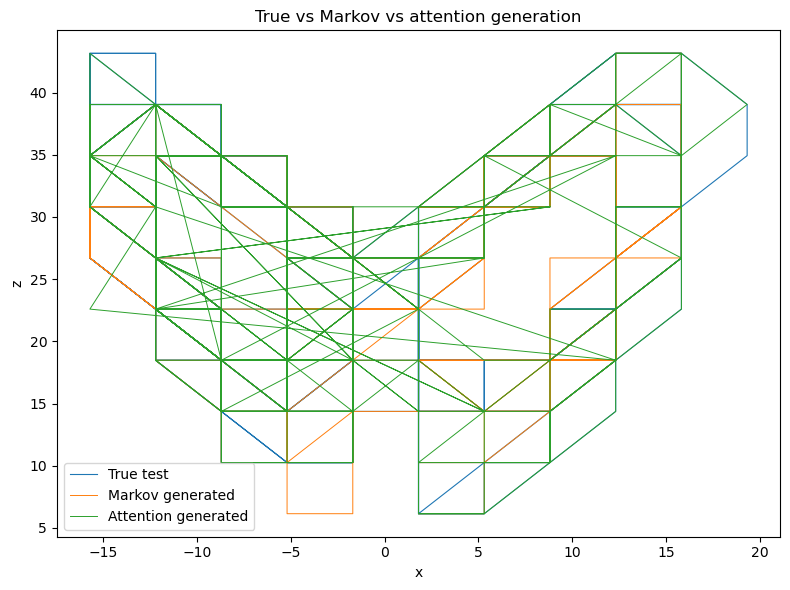

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1\step7_true_markov_attention_xz.png


In [11]:
true_states = tokens_to_centers(
    test_books[0]
)

markov_states = tokens_to_centers(
    markov_generated[0]
)

attention_states = tokens_to_centers(
    attention_generated[0]
)

plt.figure(figsize=(8, 6))

plt.plot(
    true_states[:, 0],
    true_states[:, 2],
    linewidth=0.8,
    label="True test",
)

plt.plot(
    markov_states[:, 0],
    markov_states[:, 2],
    linewidth=0.7,
    label="Markov generated",
)

plt.plot(
    attention_states[:, 0],
    attention_states[:, 2],
    linewidth=0.7,
    label="Attention generated",
)

plt.xlabel("x")
plt.ylabel("z")
plt.title("True vs Markov vs attention generation")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "step7_true_markov_attention_xz.png"
)

plt.savefig(
    path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path.resolve())

# Task 8: not applicable to the selected Lorenz system

Task 8 concerns Kirchhoff's equations and asks whether generated trajectories preserve

$$
H,
\qquad
C_1=|P|^2,
\qquad
C_2=\Pi\cdot P.
$$

This project uses the dissipative Lorenz system.

Therefore Hamiltonian energy, momentum, and Casimir preservation are not evaluated or invented for this project.

## Steps 6-8 outputs

### Attention interpretation

- `task6_attention_examples.csv`
- `task6_attention_lag_by_target.csv`
- `task6_attention_lag_summary.csv`
- `step6_attention_matrix_near_lobe_switch.png`
- `step6_attention_profile_near_lobe_switch.png`
- `step6_attention_matrix_within_one_lobe.png`
- `step6_attention_profile_within_one_lobe.png`

### Generation and Lorenz diagnostics

- `task7_markov_generated_manifest.csv`
- `task7_attention_generated_manifest.csv`
- `markov_generated_sequences/`
- `attention_generated_sequences/`
- `task7_support_comparison.csv`
- `task7_lobe_switching_comparison.csv`
- `task7_lobe_switching_summary.csv`
- `step7_true_markov_attention_xz.png`

## Audit-verified Task 7 results after equalizing the initial prefix

The original version seeded the Markov generator with 3 true tokens and the attention generator with 32 true tokens. That did not affect either fitted model, but it made the generator comparison unnecessarily asymmetric. The corrected protocol gives both generators the same 32-token held-out prefix.

The corrected result strengthens the main conclusion: the attention generator stays near the same **coarse support**, but it switches lobes much too frequently. The Markov generator matches the true coarse switching statistics far more closely.

Because the first 32 tokens are true for both generated sequences, a second diagnostic also removes that prefix before measuring switching. The conclusion is unchanged.

In [12]:
print("Corrected support comparison:")
print(pd.read_csv(DATA_DIR / "task7_support_comparison.csv").to_string(index=False))
print()
print("Corrected lobe-switching summary (same 32-token prefix):")
print((DATA_DIR / "task7_lobe_switching_summary.csv").read_text(encoding="utf-8"))
print("Post-prefix lobe-switching summary:")
print((DATA_DIR / "task7_lobe_switching_postprefix_summary.csv").read_text(encoding="utf-8"))


Corrected support comparison:
            dataset    representation  count  mean_distance  median_distance  p95_distance  fraction_within_validation_p95_threshold
          true_test token box centers  12510       0.877832         0.747042      2.220875                                  0.951079
   markov_generated token box centers 125100       0.862722         0.723608      2.220875                                  0.952022
attention_generated token box centers 125100       0.890884         0.764908      2.225257                                  0.947906

Corrected lobe-switching summary (same 32-token prefix):
,switches_per_1000_steps,switches_per_1000_steps,switches_per_1000_steps,mean_residence_time,mean_residence_time,mean_residence_time
,mean,median,std,mean,median,std
dataset,,,,,,
attention_generated,25.215999999999998,24.0,8.381590215791666,0.8505921524792306,0.8070967741935483,0.28074766510467475
markov_generated,10.76,10.4,2.0384188762743336,1.7891794223346316,1.787142857142